# ỨNG DỤNG THUẬT TOÁN PHÂN CỤM DỰA TRÊN LƯỚI STING ĐỂ PHÂN TÍCH ĐẶC ĐIỂM VÀ SỰ BIẾN ĐỘNG CỦA CÁC CHỈ SỐ QUẢN TRỊ, HÀNH CHÍNH CÔNG TẠI 63 TỈNH, THÀNH PHỐ VIỆT NAM DỰA TRÊN DỮ LIỆU PAPI GIAI ĐOẠN 2011–2024

*APPLICATION OF STING GRID-BASED CLUSTERING TO ANALYZE GOVERNANCE AND PUBLIC ADMINISTRATION PERFORMANCE PATTERNS AND TEMPORAL CHANGES ACROSS 63 VIETNAMESE PROVINCES USING PAPI DATA (2011–2024)*

**Báo cáo giữa kỳ môn Học máy · Nhóm 15 · Chủ đề 6 — Grid-based clustering**

Nguyễn Tiến Sơn (24110054) · Trần Thị Ngọc Quyên (24110051)

Notebook trình bày cơ chế gom cụm của biến thể STING do nhóm cài đặt, kiểm
chứng bằng dữ liệu giả lập và minh họa trên hai chỉ tiêu PAPI. Kết quả đã được
lưu để theo dõi trực tiếp.

**Chạy lại notebook.** Giải nén toàn bộ gói và mở notebook cạnh thư mục
`tai_lieu_kem`. Chọn **Restart Kernel** (khởi động lại kernel), sau đó
chọn **Run All** (chạy tất cả các ô từ đầu). Các ô phía sau sử dụng thư viện,
dữ liệu và mô hình được nạp hoặc tạo ở các ô trước.

In [1]:
import os
import sys
from collections import Counter
from pathlib import Path

_STING_MARKER = Path("src") / "sting.py"


def _find_project_root() -> Path:
    seeds: list[Path] = [Path.cwd().resolve()]
    for env_key in ("STING_REPO_ROOT", "SUBMISSION_DEMO_NB_PATH", "JPY_STARTUP_PATH"):
        raw = os.environ.get(env_key)
        if not raw:
            continue
        seeds.append(
            Path(raw).resolve()
            if env_key == "STING_REPO_ROOT"
            else Path(raw).resolve().parent
        )
    try:
        from IPython import get_ipython

        ip = get_ipython()
        if ip is not None:
            for key in ("__vsc_ipynb_file__", "__file__"):
                raw = ip.user_ns.get(key)
                if raw:
                    seeds.append(Path(raw).resolve().parent)
    except ImportError:
        pass
    seen: set[Path] = set()
    for seed in seeds:
        cur = seed
        for _ in range(64):
            if cur in seen:
                break
            seen.add(cur)
            for candidate in (cur / "tai_lieu_kem", cur):
                if (candidate / _STING_MARKER).is_file():
                    return candidate
            parent = cur.parent
            if parent == cur:
                break
            cur = parent
    raise FileNotFoundError(
        "Không tìm thấy mã nguồn STING. Vui lòng giải nén toàn bộ gói "
        "và giữ thư mục tai_lieu_kem cùng cấp với notebook."
    )


ROOT = _find_project_root()
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import adjusted_rand_score, silhouette_score

from sting import STING
from scripts.common.papi_pred_common import FEATURE_LABELS, load_panel
from scripts.common.fig_style import apply_style
from scripts.common.midterm_clustering import (
    FEATURES, GRID, THRESHOLDS, K_CANDIDATES, KMEANS_OPTIONS, DBSCAN_OPTIONS, CELL_Z_EXAMPLE,
    fit_grid, clustered_silhouette, comparison_figure, raw_dbscan_radius, scaling_comparison_figure,
    reference_grid_assignments, sting_steps_figure, kmeans_elbow_figure,
    noise_and_trap_figure, sensitivity_grid_figure, hierarchy_levels_figure,
    kmeans_mechanism_and_trap_figure, hc_linkage_and_dendrogram_figure,
)

apply_style()
print("Đã nạp mã nguồn STING và các thư viện cần thiết.")

Đã nạp mã nguồn STING và các thư viện cần thiết.


## 1. Lý thuyết STING

**Grid-based clustering** tìm cụm bằng cách chia không gian dữ liệu thành các ô lưới.
**STING** (Statistical Information Grid) thuộc nhóm phương pháp này và dùng lưới nhiều mức, từ thô đến mịn.
Mỗi ô lưu số điểm và các thống kê tóm tắt.

Nhóm sử dụng **biến thể STING rút gọn** để tạo cụm tại một mức lưới.

1. Gán các điểm vào lưới và đếm số điểm trong từng ô.
2. Đánh dấu ô có số điểm đạt ngưỡng là ô dày.
3. Gom mỗi vùng gồm các ô dày liên thông qua cạnh thành một cụm. Các điểm
   trong ô thưa nhận nhãn nhiễu −1.

STING gốc còn lưu loại phân phối trong các ô và duyệt lưới từ trên xuống
dựa trên độ tin cậy.

## 2. Cài đặt từ đầu — lưới 3 × 3

Ví dụ gồm 15 điểm trên một mặt phẳng. Mỗi ô có ít nhất 3 điểm được xem là ô dày.
Trong ví dụ này, hai vùng ô dày chỉ chạm góc nên được gán vào hai cụm riêng.

Số điểm trong từng ô:
[[4 3 0]
 [1 0 4]
 [0 0 3]]
2 cụm, mỗi cụm 7 điểm. 1 điểm nhiễu.


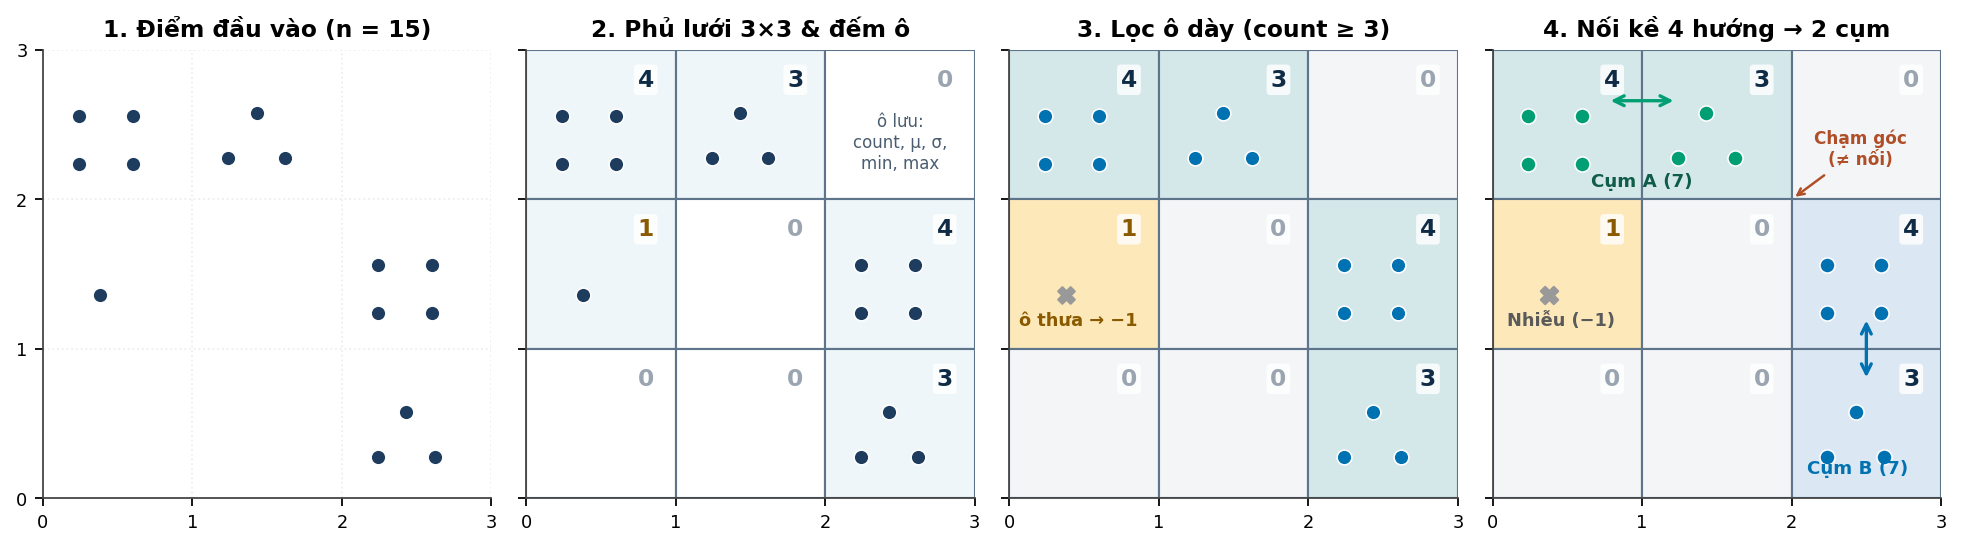

In [2]:
counts = np.array([[4, 3, 0], [1, 0, 4], [0, 0, 3]])
positions = [(col, 2 - row) for row in range(3) for col in range(3)]
points = np.repeat(positions, counts.ravel(), axis=0)
model = STING(n_levels=2, factor=3, min_count=3).fit(points)
labels = model.cluster(level=1, connectivity=1)

cell_counts = np.zeros_like(counts)
for (x, y), cell in model.cells_[1].items():
    cell_counts[2 - y, x] = cell.count
print("Số điểm trong từng ô:")
print(cell_counts)
assert np.array_equal(cell_counts, counts)

group_sizes = sorted(np.bincount(labels[labels >= 0]).tolist())
noise_count = int((labels == -1).sum())
assert group_sizes == [7, 7] and noise_count == 1
print(f"{model.n_clusters_} cụm, mỗi cụm {group_sizes[0]} điểm. {noise_count} điểm nhiễu.")
fig = sting_steps_figure()
plt.show()

## 3. Đánh giá trên dữ liệu giả lập

Nhóm sinh 240 điểm từ hai phân bố Gauss. Nhãn khi sinh dữ liệu là căn cứ
để tính Adjusted Rand Index (ARI) và kiểm tra mức độ khớp của kết quả phân cụm.

ARI = 0.950 | Số cụm 2 | Tỷ lệ nhiễu 2.5%


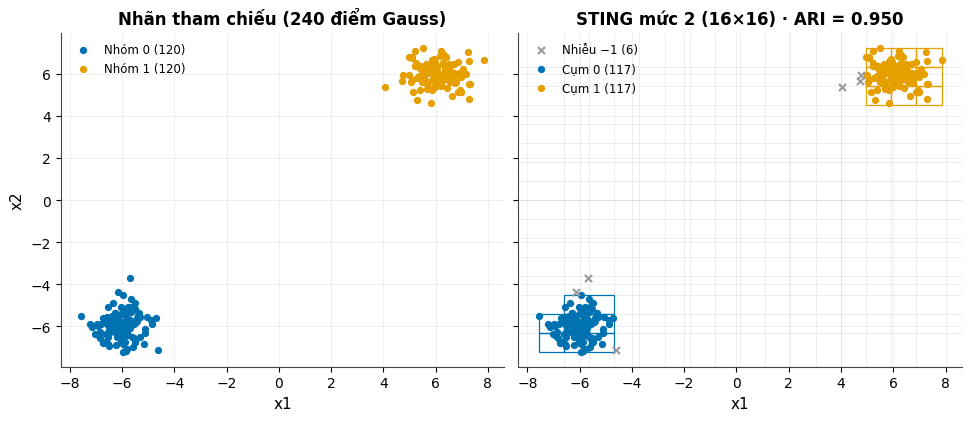

In [3]:
from matplotlib.patches import Rectangle
from scripts.common.fig_style import CLUSTER_COLORS, PALETTE

X_syn, y_true = make_blobs(n_samples=240, centers=[(-6, -6), (6, 6)],
                           cluster_std=0.6, random_state=42)
m_syn = STING(n_levels=3, factor=4, min_count=3).fit(X_syn)
lab_syn = m_syn.cluster(level=2, connectivity=1)
ari = adjusted_rand_score(y_true, lab_syn)
assert ari >= 0.9, f"ARI quá thấp: {ari:.3f}"
print(f"ARI = {ari:.3f} | Số cụm {m_syn.n_clusters_} | Tỷ lệ nhiễu {(lab_syn == -1).mean():.1%}")

res_syn = m_syn.factor ** 2
lo_s, hi_s = m_syn.bounds_min_, m_syn.bounds_max_
step_s = (hi_s - lo_s) / res_syn
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.1), sharex=True, sharey=True, layout="constrained")
for gid in sorted(set(y_true)):
    mk = y_true == gid
    axes[0].scatter(X_syn[mk, 0], X_syn[mk, 1], s=18, color=CLUSTER_COLORS[gid], label=f"Nhóm {gid} ({int(mk.sum())})")
axes[0].set_title("Nhãn tham chiếu (240 điểm Gauss)")
axes[0].set_xlabel("x1")
axes[0].set_ylabel("x2")
axes[0].grid(alpha=0.18)
axes[0].legend(loc="upper left", fontsize=8.5)

for i in range(1, res_syn):
    axes[1].axvline(lo_s[0] + i * step_s[0], color="#DCE4EC", linewidth=0.45, zorder=0.5)
    axes[1].axhline(lo_s[1] + i * step_s[1], color="#DCE4EC", linewidth=0.45, zorder=0.5)
for idx, cid in m_syn.label_of_.items():
    cell = m_syn.cells_[2][idx]
    axes[1].add_patch(Rectangle(cell.bounds_min, *(cell.bounds_max - cell.bounds_min),
                                facecolor="none", edgecolor=CLUSTER_COLORS[cid], linewidth=0.9, zorder=1.5))
ns = lab_syn == -1
axes[1].scatter(X_syn[ns, 0], X_syn[ns, 1], s=26, color=PALETTE["gray"], marker="x",
                label=f"Nhiễu −1 ({int(ns.sum())})", zorder=3)
for cid in sorted(set(lab_syn[lab_syn >= 0])):
    mk = lab_syn == cid
    axes[1].scatter(X_syn[mk, 0], X_syn[mk, 1], s=18, color=CLUSTER_COLORS[cid],
                    label=f"Cụm {cid} ({int(mk.sum())})", zorder=2.5)
axes[1].set_title(f"STING mức 2 (16×16) · ARI = {ari:.3f}")
axes[1].set_xlabel("x1")
axes[1].grid(alpha=0.18)
axes[1].legend(loc="upper left", fontsize=8.5)
plt.show()


## 4. Phân cụm trên dữ liệu PAPI 2011–2024

Mỗi điểm là một tỉnh trong một năm. Hai tọa độ là chỉ tiêu **4.2 Kiểm soát tham
nhũng trong cung ứng dịch vụ công** và **6.1 Y tế công lập**. Mục tiêu là mô tả
vùng điểm tập trung và các vùng nhỏ tách biệt trên mặt phẳng hai chỉ tiêu.

Các tỉnh có đủ hai chỉ tiêu năm 2024 được đưa vào phân tích cùng dữ liệu các năm trước.
Các cụm mô tả những quan sát đã có trong bảng PAPI.

### 4.1 Chuẩn bị mẫu phân tích

In [4]:
feats = list(FEATURES)
panel = load_panel()
keys = ["province_code", "year"]
assert panel.shape == (882, 41)
assert not panel.duplicated(keys).any()
assert not (panel[feats] == 0).any().any()
complete = panel.dropna(subset=feats).copy()
total_2024 = int(panel.year.eq(2024).sum())
eligible_2024 = int(complete.year.eq(2024).sum())

prep = pd.read_csv(ROOT / "results" / "preprocessing_audit.csv")
outlier_result = prep.loc[prep["test"].str.startswith("Đánh dấu ngoại lai"), "result"].item()
print(f"PAPI có {len(panel)} dòng, {panel.shape[1]} cột và {panel.province_code.nunique()} tỉnh.")
print(f"Mẫu phân cụm gồm {len(complete)} quan sát đủ hai chỉ tiêu, loại {len(panel) - len(complete)} dòng thiếu.")
print(f"Năm 2024 đóng góp {eligible_2024}/{total_2024} quan sát vào cùng mẫu phân cụm.")
print(f"Kiểm tra ngoại lai khi tiền xử lý: {outlier_result}. Giữ điểm PAPI để phân cụm.")

prep_view = prep[["stage", "test", "result", "decision"]].rename(columns={
    "stage": "Giai đoạn", "test": "Kiểm tra", "result": "Kết quả", "decision": "Quyết định",
})
prep_view["Kiểm tra"] = prep_view["Kiểm tra"].str.replace(", dedup chạy ĐẦU TIÊN", "", regex=False)
with pd.option_context("display.max_colwidth", None):
    display(prep_view)

PAPI có 882 dòng, 41 cột và 63 tỉnh.
Mẫu phân cụm gồm 869 quan sát đủ hai chỉ tiêu, loại 13 dòng thiếu.
Năm 2024 đóng góp 61/63 quan sát vào cùng mẫu phân cụm.
Kiểm tra ngoại lai khi tiền xử lý: 122 ô (0.4%), 98 dòng, 29 cột. Giữ điểm PAPI để phân cụm.


,Giai đoạn,Kiểm tra,Kết quả,Quyết định
0,1. Cleaning — (a) trùng khóa,"Trùng khóa (province_code, year)",0 dòng trùng / 882 dòng (882 khóa duy nhất); trùng toàn dòng: 0,Giữ đúng 1 dòng/khóa. Pipeline chặn cứng nếu phát hiện trùng (không tự bỏ dòng) — dedup nằm ở bước đầu của Cleaning.
1,1. Cleaning — (b) giá trị thiếu,Ô thiếu trong 37 cột chỉ tiêu (8 chiều + tiểu chiều),4649/32634 ô (14.2%); 4284 ô nằm NGOÀI cửa sổ thu thập của cột (d7/sd_7_*/sd_8_*/sd_5_2),"KHÔNG nội suy, không điền: giữ NaN. Chỉ loại dòng khi ghép cặp / dựng ma trận feature."
2,1. Cleaning — (b) giá trị thiếu,Dòng thiếu ≥1 chỉ tiêu TRONG cửa sổ thu thập,"13/882 dòng, 365 ô; 13 dòng thiếu sd_4_2 hoặc sd_6_1","Loại khỏi train/dự đoán bằng dropna trên đúng cột đang dùng; không điền, không nội suy."
3,1. Cleaning — (c) nhất quán,Tên tỉnh vs crosswalk 63 tỉnh,0 xung đột; 63/63 mã khớp crosswalk,Tên/mã lấy từ crosswalk; mã không map được là lỗi chặn (build dừng).
4,1. Cleaning — (c) nhất quán,Khoảng giá trị vs metadata thang đo,0 ô ngoài khoảng / 32634 ô (37 cột × 882 dòng),"Giữ nguyên giá trị; không cắt, không sửa theo metadata."
5,1. Cleaning — (c) nhất quán,Giá trị ngoài cửa sổ thu thập của từng cột,0 ô,"Giữ; cửa sổ năm là metadata kiểm chứng, không dùng để xóa ô."
6,1. Cleaning — (c) nhất quán,Điểm 0.0 (quy ước 'tỉnh không được xếp hạng'),0 ô điểm = 0.0 còn lại,0.0 → NaN ngay khi dựng panel để không lẫn với điểm thật.
7,1. Cleaning — (d) ngoại lai (CUỐI CÙNG),Đánh dấu ngoại lai z-score > 3 (trị tuyệt đối),"122 ô (0.4%), 98 dòng, 29 cột","GIỮ toàn bộ — chỉ đánh dấu, không xóa. Cờ z-score không quyết định nhãn STING; điểm nhận -1 khi không thuộc ô dày hoặc ngoài vùng lưới đã học. Dữ liệu gốc không bị loại."
8,2. Integration — khóa nối,Khóa nối duy nhất hai phía + quan hệ bản ghi,panel 0 trùng; master 0 trùng; quan hệ one_to_one (không one-to-many/many-to-many),"Nối one-to-one theo (province_code, year); không nhân dòng."
9,2. Integration — số dòng,Số dòng trước/sau khi nối panel × master,882 → 882; 63 tỉnh; lưới khóa giống nhau: True,"LEFT join giữ đúng lưới panel; ô dữ liệu bên ngoài thiếu để trống, có mask."


### 4.2 Tính z-score từ số liệu thật

Điểm 0 đã được chuyển sang giá trị thiếu theo quy ước nguồn. Với mỗi chỉ tiêu,
nhóm tính trung bình **μ** và độ lệch chuẩn **σ** trên các quan sát đủ cả hai
chỉ tiêu. Tọa độ được chuẩn hóa bằng **z = (x − μ) / σ**, với σ tính theo
quy ước chia cho số quan sát n của StandardScaler. Trên hình, z = 0 là mức
trung bình của chỉ tiêu đó và z = +1 là cao hơn trung bình một độ lệch chuẩn.
Hai trục cùng dùng đơn vị độ lệch chuẩn.

Ô dưới lấy Lạng Sơn năm 2024 làm ví dụ. Sau chuẩn hóa, tọa độ 4.2 bằng 0,9005
nghĩa là chỉ tiêu này cao hơn trung bình khoảng 0,90 độ lệch chuẩn. Tọa độ
6.1 bằng 0,3737 nghĩa là y tế công lập cao hơn trung bình khoảng 0,37 độ
lệch chuẩn. Hai tọa độ tạo thành đầu vào chung cho cả ba thuật toán.

In [5]:
scores = complete[feats]
Xraw = scores.to_numpy()
scaler = StandardScaler().fit(scores)
Xz = scaler.transform(scores)

example_mask = complete.province_vi.eq("Lạng Sơn") & complete.year.eq(2024)
example = scores.loc[example_mask].iloc[0].to_numpy()
means = scores.mean().to_numpy()
stds = scores.std(ddof=0).to_numpy()
z_example = (example - means) / stds
np.testing.assert_allclose(z_example, scaler.transform(scores.loc[example_mask])[0])
print("Lạng Sơn năm 2024")
for feature, x, mu, sigma, z in zip(feats, example, means, stds, z_example, strict=True):
    print(f"{feature}: ({x:.6f} − {mu:.6f}) / {sigma:.6f} = {z:.4f}")

display(pd.DataFrame({
    "Chỉ tiêu": [FEATURE_LABELS[f] for f in feats],
    "Điểm gốc x": example,
    "Trung bình μ": means,
    "Độ lệch chuẩn σ": stds,
    "z-score": z_example,
}).round(4))

Lạng Sơn năm 2024
sd_4_2: (2.072702 − 1.908406) / 0.182448 = 0.9005
sd_6_1: (1.959565 − 1.908428) / 0.136835 = 0.3737


,Chỉ tiêu,Điểm gốc x,Trung bình μ,Độ lệch chuẩn σ,z-score
0,4.2 Kiểm soát tham nhũng trong cung ứng dịch v...,2.0727,1.9084,0.1824,0.9005
1,6.1 Y tế công lập,1.9596,1.9084,0.1368,0.3737


### 4.3 STING tìm được ba cụm như thế nào?

Tại mức 2, mỗi trục có 4² = 16 khoảng, tạo lưới 16 × 16. Một ô có ít nhất
**5 quan sát** là ô dày. Các ô dày nối được với nhau qua cạnh tạo thành một
cụm. Dấu và độ lớn của z-score chỉ xác định tọa độ của điểm. Quy tắc nhiễu
dựa vào **số điểm trong ô** mà điểm rơi vào.

**Vì sao dùng ngưỡng 5?** Cặp chỉ tiêu, độ mịn và ngưỡng được chọn cùng
nhau trong khảo sát cấu hình trên dữ liệu đến 2020, đối chiếu độ phủ
trên 2021–2022. Bộ lọc xét các cấu hình có từ 2 đến 6 cụm và điểm chọn
ưu tiên kết quả gần 3 cụm. Ở bước gom ô, số cụm được đếm từ các thành
phần liên thông. Mục 4.7 thay từng tham số để thấy kết quả đổi thế nào.

Bản nhóm lưu thống kê ở ba mức rồi chọn một mức để gom các ô dày.
STING gốc lưu cả loại phân phối và dùng khoảng tin cậy để duyệt các
ô con của ô cha được giữ ở bước truy vấn.

Để tính ô trên một trục, lấy phần nguyên dưới của
**r × (x − min) / (max − min)** với r là số ô trên trục. Chỉ số bắt đầu
từ 0 và điểm đúng biên trên rơi vào ô cuối có chỉ số r − 1.

**Phân biệt ba bước lọc và đánh dấu (vì sao tiền xử lý xong vẫn còn nhãn −1):**

| Bước | Tiêu chí | Số lượng trên mẫu PAPI | Xử lý |
|---|---|---|---|
| Lọc thiếu (`dropna`) | Thiếu chỉ tiêu `4.2` hoặc `6.1` | `13/882` dòng (năm 2024: Vĩnh Phúc, Tiền Giang) | Loại khỏi ma trận tọa độ, giữ `869` quan sát đủ hai điểm hợp lệ. |
| Ngoại lai đơn biến | `\|z\| > 3` trên từng trục | `9/869` quan sát | Chỉ đánh dấu, không xóa vì là điểm khảo sát thật trong thang đo PAPI. |
| Nhiễu STING (`−1`) | Ô lưới `16 × 16` có `< 5` điểm | `171/869` quan sát (`162/171` có `\|z\| ≤ 3` cả hai trục) | Đầu ra của thuật toán cho các điểm hợp lệ nằm ở vùng thưa. |

Vì `−1` đo mật độ đồng thời trong ô lưới chứ không phải điểm lỗi trên một trục, kể cả nếu bỏ 9 điểm `|z| > 3` rồi dựng lại lưới trên 860 điểm còn lại, biên `min–max` co lại làm ô nhỏ hơn và vẫn có `173/860` điểm (`20,1%`) rơi vào ô thưa.

Ô dưới in số ô dày và số quan sát trong từng cụm. Hàm thiết lập lưới gọi
STING.fit để đếm điểm và STING.cluster để gom các ô dày kề cạnh.

In [6]:
grid_model, lab = fit_grid(Xz)
points_per_cluster = Counter(lab)
cells_per_cluster = Counter(grid_model.label_of_.values())
cell_stats = grid_model.cells_[grid_model.cluster_level_]
grid_width = GRID["factor"] ** GRID["cluster_level"]

print(f"Lưới {grid_width} × {grid_width} | Bốn hướng kề cạnh | Ngưỡng {grid_model.min_count_} điểm/ô")
print(f"{len(grid_model.label_of_)} ô dày tạo thành {grid_model.n_clusters_} vùng liên thông.")
for group in sorted(cells_per_cluster):
    print(f"Cụm {group}: {cells_per_cluster[group]} ô dày, {points_per_cluster[group]} quan sát.")
noise = points_per_cluster[-1]
print(f"Nhiễu: {noise}/{len(lab)} quan sát ({noise / len(lab):.1%}).")
z_flag = (np.abs(Xz) > 3).any(axis=1)
sparse_without_flag = int(((lab == -1) & ~z_flag).sum())
print(f"{z_flag.sum()} quan sát có |z| > 3 trên ít nhất một trục. "
      f"{sparse_without_flag}/{noise} điểm nhãn −1 có |z| ≤ 3 trên cả hai trục.")
trimmed_grid, trimmed_lab = fit_grid(Xz[~z_flag])
trimmed_noise = int((trimmed_lab == -1).sum())
print(f"Nếu loại {z_flag.sum()} điểm |z| > 3 rồi dựng lại lưới trên {len(trimmed_lab)} điểm: "
      f"{trimmed_grid.n_clusters_} cụm, {trimmed_noise}/{len(trimmed_lab)} điểm nhiễu "
      f"({trimmed_noise / len(trimmed_lab):.1%}).")

step = (grid_model.bounds_max_ - grid_model.bounds_min_) / grid_width
bin_indices = np.floor((z_example - grid_model.bounds_min_) / step).astype(int)
example_cell = tuple(np.clip(bin_indices, 0, grid_width - 1).tolist())
np.testing.assert_array_equal(
    example_cell, grid_model.point_cell_index(grid_model.cluster_level_)[example_mask.to_numpy()][0],
)
assert grid_model.label_of_.get(example_cell, -1) == lab[example_mask.to_numpy()][0]
print(f"Lạng Sơn 2024 vào ô {example_cell} (đếm từ 0), ô có {cell_stats[example_cell].count} quan sát.")
print(f"Nhãn cụm của điểm này: {grid_model.label_of_.get(example_cell, -1)}.")

Lưới 16 × 16 | Bốn hướng kề cạnh | Ngưỡng 5 điểm/ô
56 ô dày tạo thành 3 vùng liên thông.
Cụm 0: 1 ô dày, 5 quan sát.
Cụm 1: 3 ô dày, 16 quan sát.
Cụm 2: 52 ô dày, 677 quan sát.
Nhiễu: 171/869 quan sát (19.7%).
9 quan sát có |z| > 3 trên ít nhất một trục. 162/171 điểm nhãn −1 có |z| ≤ 3 trên cả hai trục.
Nếu loại 9 điểm |z| > 3 rồi dựng lại lưới trên 860 điểm: 4 cụm, 173/860 điểm nhiễu (20.1%).
Lạng Sơn 2024 vào ô (12, 10) (đếm từ 0), ô có 17 quan sát.
Nhãn cụm của điểm này: 2.


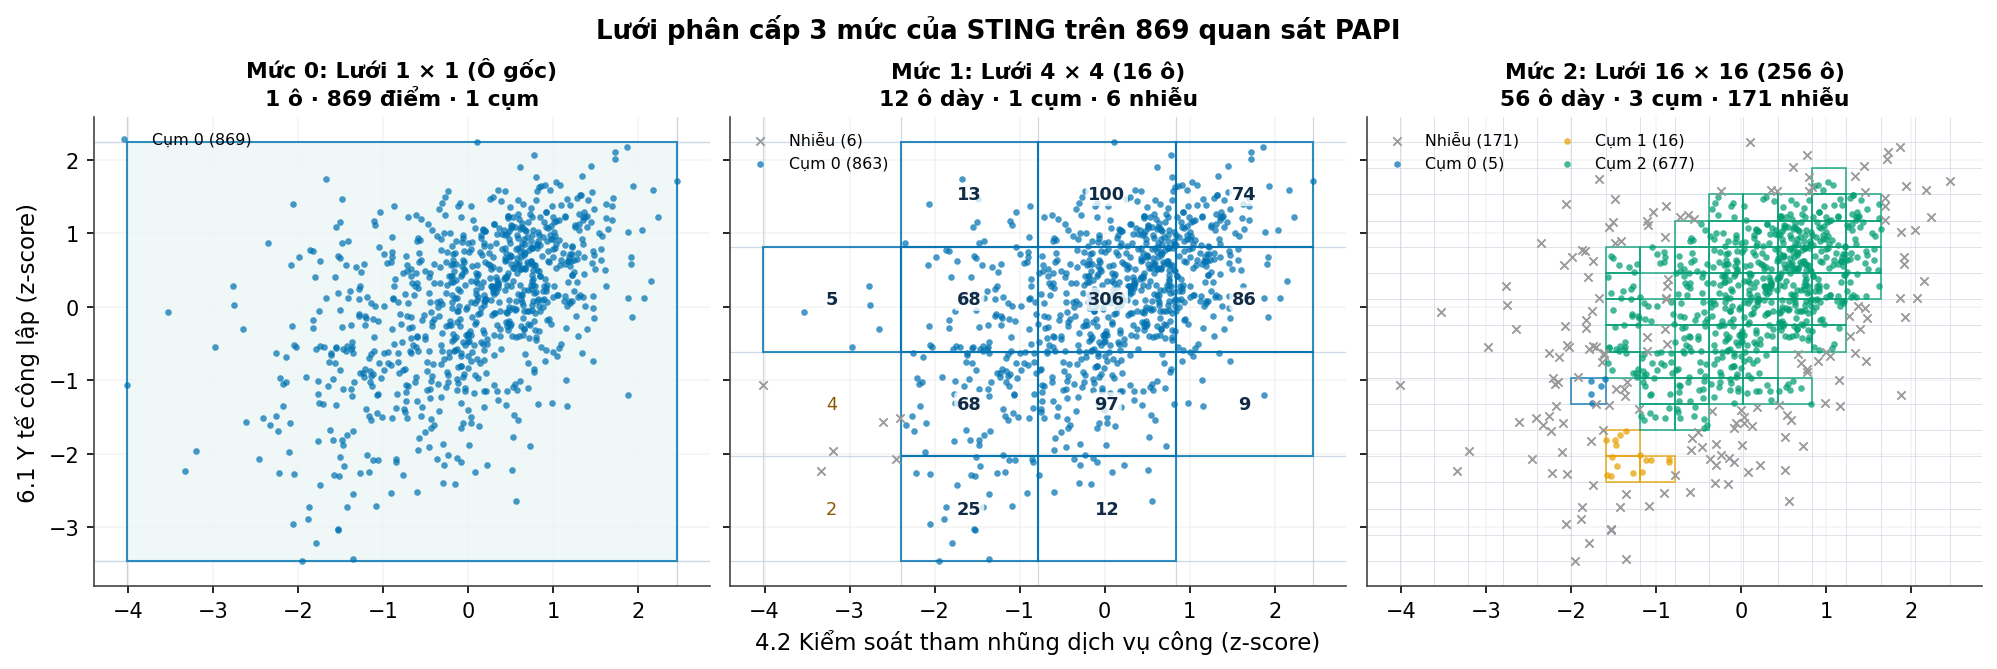

In [7]:
fig = hierarchy_levels_figure(Xz)
plt.show()

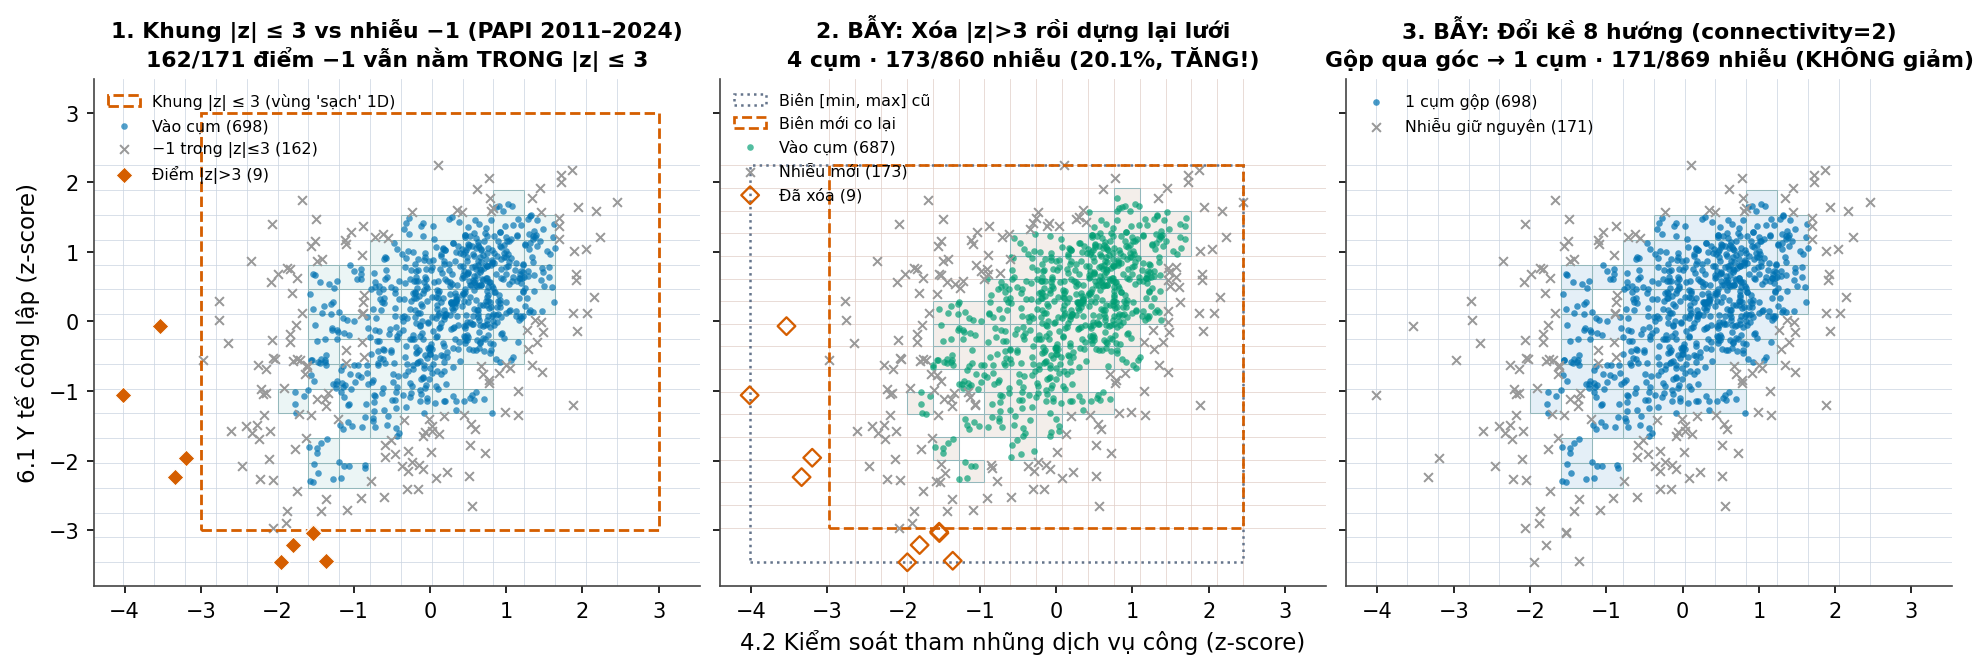

In [8]:
fig = noise_and_trap_figure(Xz, grid_model, lab, title_prefix="PAPI 2011–2024")
plt.show()

### 4.4 Vì sao K-means dùng k = 2?

K-means cần chỉ định số cụm k và gán mỗi điểm vào tâm cụm gần nhất. Nhóm
thử k từ 2 đến 5 trên **cùng 869 điểm sau chuẩn hóa**. Silhouette đo độ
gần của mỗi điểm với cụm của nó so với cụm gần nhất khác. Điểm càng gần 1,
sự phân tách càng rõ theo khoảng cách Euclid. Nhóm dùng k có điểm cao nhất
trong bốn giá trị đã thử để vẽ và đối chiếu.

Trên hình STING, các hình chữ nhật đánh dấu ô dày. Cụm của STING được
đếm từ các vùng ô dày, còn số cụm K-means được chọn qua bảng silhouette.
Code cũng lấy lại tọa độ z-score của Lạng Sơn để tính khoảng cách Euclid
đến các tâm. Qua đó có thể đối chiếu cách gán điểm này với cách STING chọn ô.

In [9]:
models = {}
silhouette_by_k = {}
for k in K_CANDIDATES:
    fitted = KMeans(n_clusters=k, **KMEANS_OPTIONS).fit(Xz)
    models[k] = fitted
    silhouette_by_k[k] = silhouette_score(Xz, fitted.labels_)
    print(f"k={k}  |  Silhouette = {silhouette_by_k[k]:.4f}")

best_k = max(silhouette_by_k, key=silhouette_by_k.get)
km = models[best_k]
print(f"K-means chọn k={best_k} trong các giá trị đã thử và gán đủ {len(km.labels_)} điểm.")
distances = np.linalg.norm(km.cluster_centers_ - z_example, axis=1)
assert distances.argmin() == km.labels_[example_mask.to_numpy()][0]
print("Khoảng cách từ Lạng Sơn 2024 đến các tâm, theo thứ tự gần đến xa: "
      + " và ".join(f"{distance:.4f}" for distance in sorted(distances)))

k=2  |  Silhouette = 0.4472
k=3  |  Silhouette = 0.3354


k=4  |  Silhouette = 0.3649
k=5  |  Silhouette = 0.3311
K-means chọn k=2 trong các giá trị đã thử và gán đủ 869 điểm.
Khoảng cách từ Lạng Sơn 2024 đến các tâm, theo thứ tự gần đến xa: 0.4052 và 2.2139


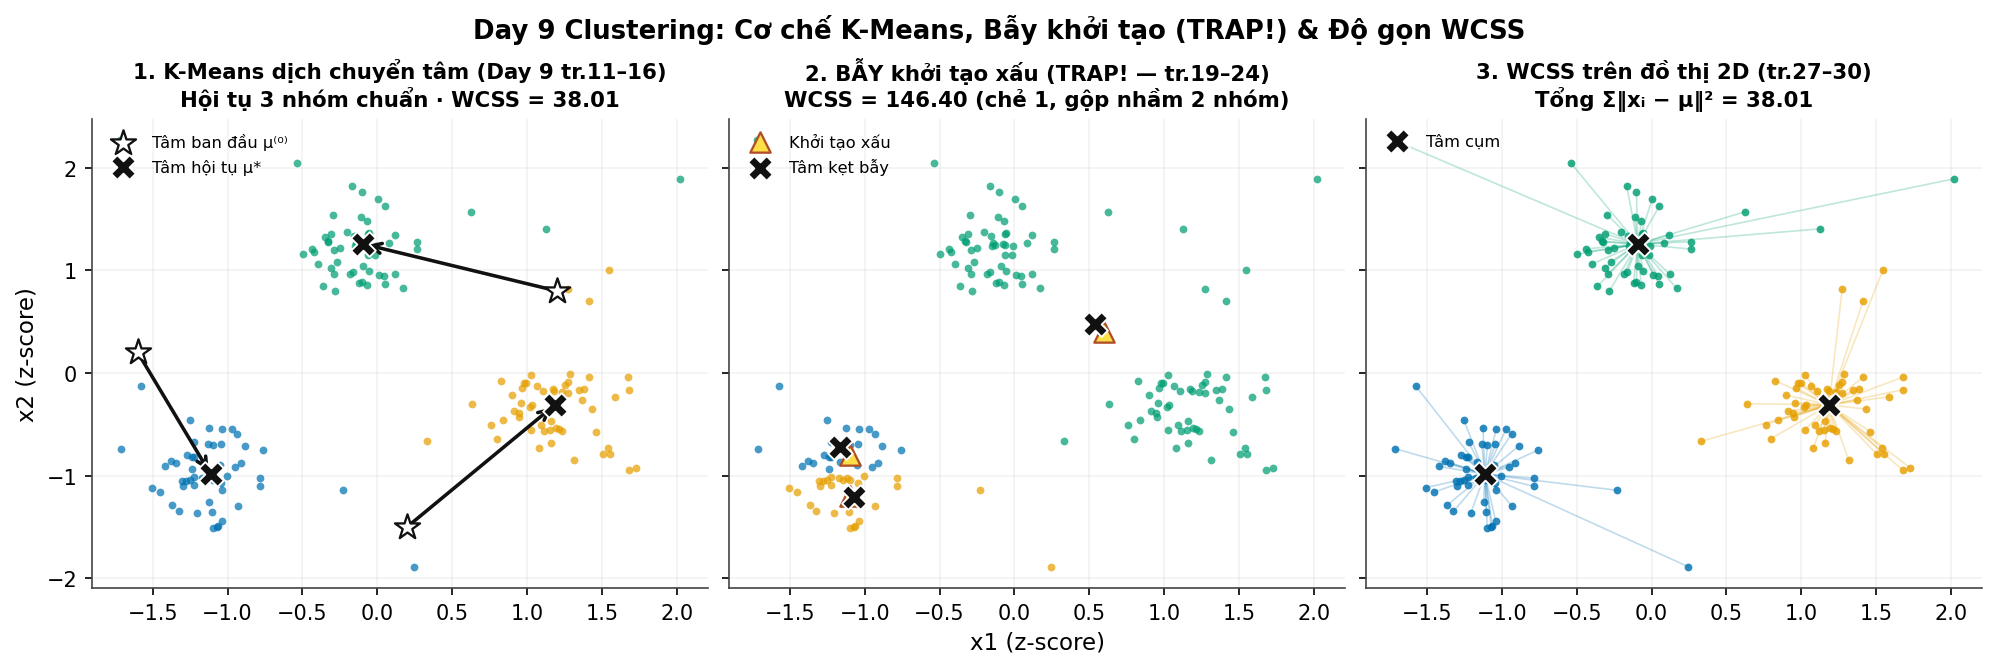

In [10]:
fig = kmeans_mechanism_and_trap_figure()
plt.show()

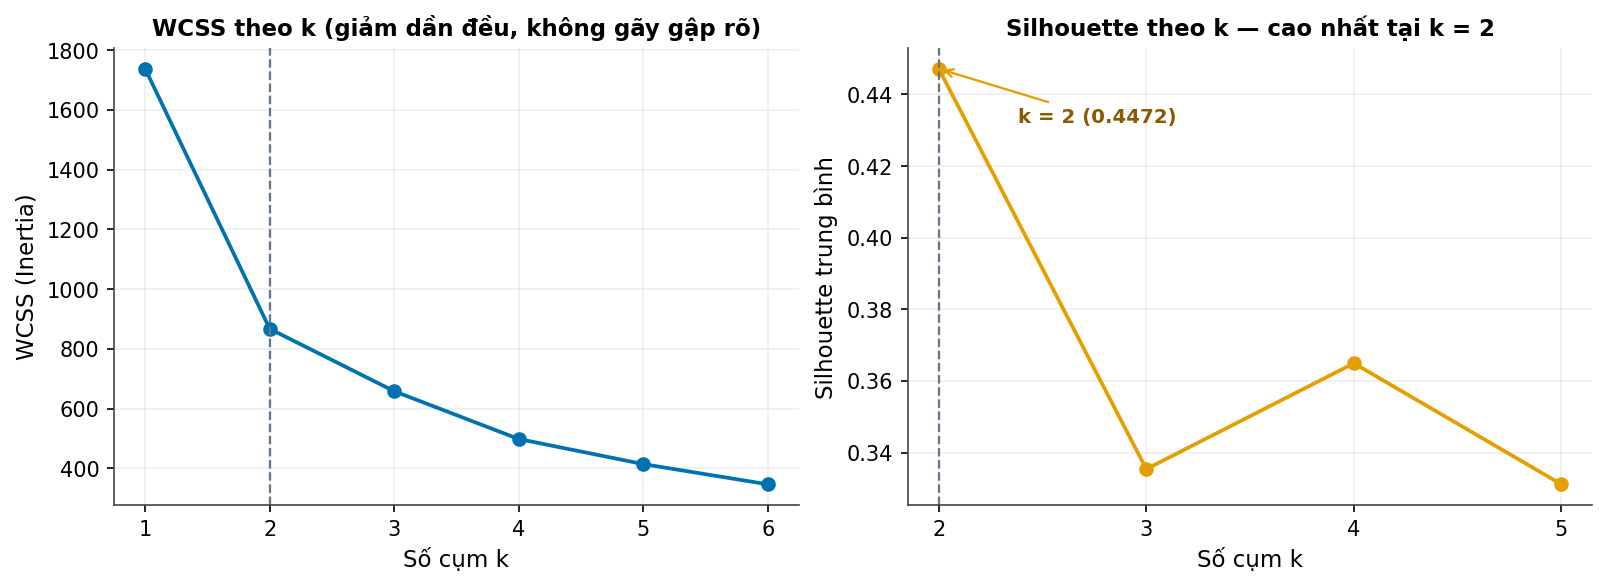

In [11]:
fig = kmeans_elbow_figure(Xz)
plt.show()

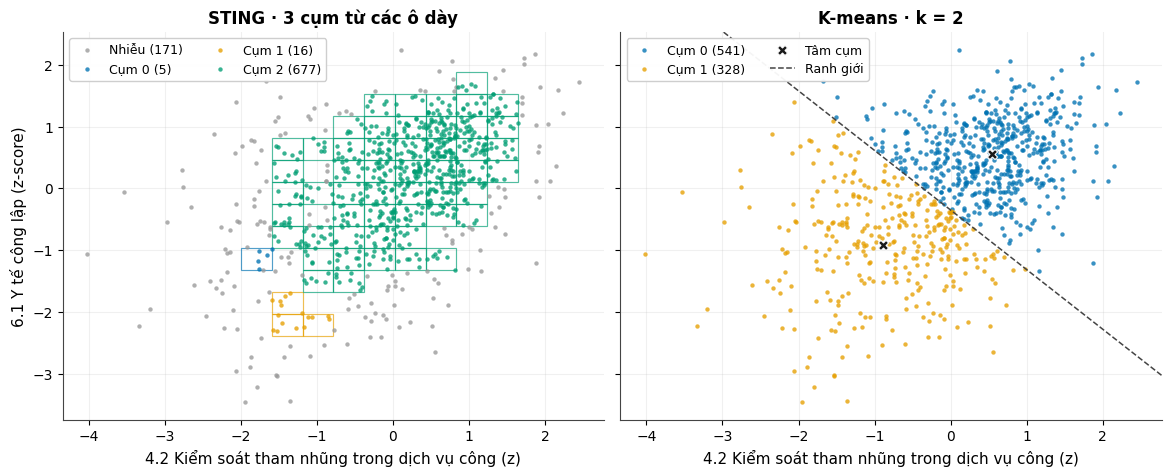

In [12]:
fig = comparison_figure(Xz, grid_model, lab, km)
plt.show()

### 4.5 Đối chiếu trên cùng nhóm quan sát

| Cách tạo cụm | Tiêu chí | Tham số chính trong bài |
|---|---|---|
| STING | Số điểm trong từng ô. Các ô dày kề cạnh tạo thành một cụm. | Lưới 16 × 16, tối thiểu 5 điểm/ô, kề theo 4 hướng. |
| K-means | Gán mọi điểm cho tâm gần nhất, giảm tổng bình phương khoảng cách đến tâm. | Thử k = 2–5 trên cùng dữ liệu. Giữ thêm k = 3 để đối chiếu cùng số cụm với STING. |
| DBSCAN | Xét mật độ lân cận quanh từng điểm. Nối các vùng qua điểm lõi. | ε = 0,2 theo khoảng cách Euclid trên tọa độ z-score, tối thiểu 5 điểm trong lân cận tính cả điểm đang xét. |

Cả ba chạy trên 869 điểm sau chuẩn hóa. Khi so **silhouette**, lấy phần giao
các điểm được cả ba phương pháp gán cụm. Dùng cùng tọa độ z-score, cùng
khoảng cách Euclid và giữ nguyên nhãn đã gán trên mẫu 869. Bảng kèm số
điểm nhiễu trên toàn mẫu và số cụm còn trong phần giao để đọc cùng điểm số.

Với một điểm, a là khoảng cách trung bình tới các điểm còn lại trong cùng
cụm và b là khoảng cách trung bình nhỏ nhất tới một cụm khác. Silhouette
của điểm là **(b − a) / max(a, b)**. PAPI được đánh giá theo độ gọn và tách
trên phần giao vì nhãn cụm chuẩn chỉ có ở ví dụ giả lập. Tỷ lệ nhiễu và kích
thước cụm giúp đọc kết quả trên toàn bộ 869 điểm.

Hai điểm silhouette của cùng một K-means k = 2 có vai trò riêng.
**0,4472 trên 869 điểm** là kết quả dùng khi chọn k trong mục 4.4.
**0,4605 trên 680 điểm** là kết quả đối chiếu với STING và DBSCAN.

In [13]:
db = DBSCAN(**DBSCAN_OPTIONS).fit(Xz)
assignments = {
    "STING": lab,
    f"K-means k={best_k}": km.labels_,
    "DBSCAN": db.labels_,
}
common = np.logical_and.reduce([labels >= 0 for labels in assignments.values()])

assignments["K-means k=3"] = models[3].labels_
print(f"Silhouette trên cùng {common.sum()}/{len(lab)} điểm, giữ nhãn đã gán trên mẫu đầy đủ.")
sting_noise = lab == -1
dbscan_noise = db.labels_ == -1
both_noise = int((sting_noise & dbscan_noise).sum())
print(f"Phần giao: {len(lab)} − ({sting_noise.sum()} + {dbscan_noise.sum()} − {both_noise}) = {common.sum()}.")
rows = []
for name, labels in assignments.items():
    assigned = labels >= 0
    n_noise = int((~assigned).sum())
    sil_full = clustered_silhouette(Xz, labels)
    sil_common = silhouette_score(Xz[common], labels[common])
    print(f"{name} | silhouette cùng tập = {sil_common:.4f}")
    rows.append((name, len(set(labels[assigned])), n_noise, int(assigned.sum()), sil_full,
                 len(set(labels[common])), sil_common))

comparison = pd.DataFrame(rows, columns=[
    "Phương pháp", "Cụm toàn mẫu", "Điểm nhiễu", "Điểm vào cụm",
    "Silhouette riêng", "Cụm phần giao", "Silhouette chung",
])
display(comparison.round(4))

Silhouette trên cùng 680/869 điểm, giữ nhãn đã gán trên mẫu đầy đủ.
Phần giao: 869 − (171 + 120 − 102) = 680.
STING | silhouette cùng tập = 0.3802
K-means k=2 | silhouette cùng tập = 0.4605
DBSCAN | silhouette cùng tập = 0.2740
K-means k=3 | silhouette cùng tập = 0.3499


,Phương pháp,Cụm toàn mẫu,Điểm nhiễu,Điểm vào cụm,Silhouette riêng,Cụm phần giao,Silhouette chung
0,STING,3,171,698,0.3759,3,0.3802
1,K-means k=2,2,0,869,0.4472,2,0.4605
2,DBSCAN,6,120,749,0.1682,3,0.2740
3,K-means k=3,3,0,869,0.3354,3,0.3499


**Đối chiếu các cụm trên cùng từng điểm.** Bảng chéo dùng cả 869 quan sát.
Mỗi ô cho biết số điểm vừa thuộc một hàng STING vừa thuộc một cột K-means.
Số hiệu cụm chỉ định danh trong từng phương pháp. Đọc hàng của cụm STING
lớn nhất để thấy K-means chia vùng dày này ra sao, kể cả khi đặt k = 3.

In [14]:
biggest = max(cells_per_cluster, key=points_per_cluster.get)
for k in (2, 3):
    table = pd.crosstab(lab, models[k].labels_, rownames=["STING (−1 là nhiễu)"],
                        colnames=[f"K-means k={k}"], margins=True, margins_name="Tổng")
    sizes = sorted(table.loc[biggest].drop("Tổng").tolist(), reverse=True)
    print(f"Cụm STING lớn nhất: {points_per_cluster[biggest]} điểm. "
          f"K-means k={k} chia các điểm này thành {' + '.join(map(str, sizes))}.")
    display(table)

Cụm STING lớn nhất: 677 điểm. K-means k=2 chia các điểm này thành 482 + 195.


K-means k=2,0,1,Tổng
STING (−1 là nhiễu),,,
-1,59,112,171
0,0,5,5
1,0,16,16
2,482,195,677
Tổng,541,328,869


Cụm STING lớn nhất: 677 điểm. K-means k=3 chia các điểm này thành 306 + 303 + 68.


K-means k=3,0,1,2,Tổng
STING (−1 là nhiễu),,,,
-1,44,88,39,171
0,0,5,0,5
1,0,16,0,16
2,303,68,306,677
Tổng,347,177,345,869


**Liên hệ Hierarchical Clustering (Linkage & Dendrogram).** Ngoài STING,
K-means và DBSCAN, phương pháp phân cụm phân cấp từ dưới lên (Agglomerative)
đo khoảng cách giữa hai cụm qua 4 quy tắc (`Single`, `Complete`, `Centroid`,
`Average`) và chọn số cụm bằng đường cắt ngang trên Dendrogram ở khoảng
trống chiều cao lớn nhất.

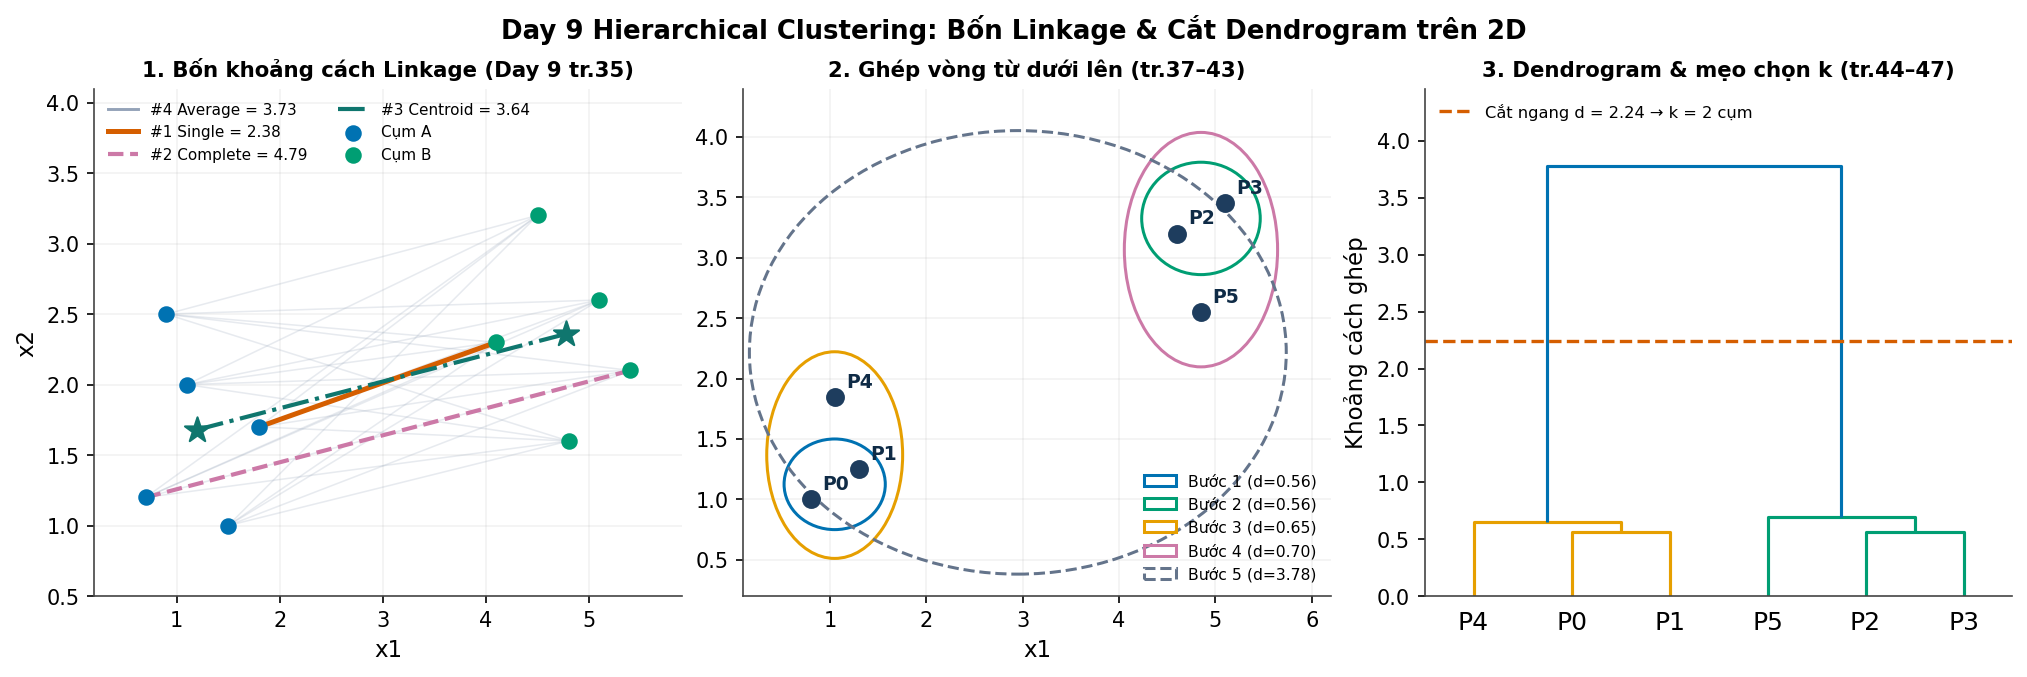

In [15]:
fig = hc_linkage_and_dendrogram_figure()
plt.show()

### 4.6 Cùng thuật toán, trước và sau z-score

**STING.** Bản cài đặt dựng lại biên lưới theo min và max của từng trục.
Vị trí tương đối trên một trục là **(x − min) / (max − min)**. Khi đổi sang
z-score, x và cả hai biên đều trừ cùng μ và chia cùng σ. Vị trí tương đối
giữ nguyên theo công thức với trục có σ > 0. Với cùng độ phân giải,
ngưỡng và quy tắc kề cạnh, các ô giữ cùng điểm và ghép thành cùng cụm.
Phép đếm trên PAPI minh họa tính chất này khi dựng lại cả hai biên lưới.

**K-means.** Sau chuẩn hóa, độ chênh của từng chỉ tiêu khi tính khoảng cách
Euclid được chia cho σ riêng của chỉ tiêu đó. Hai chỉ tiêu có σ khác nhau
nên trọng số khoảng cách thay đổi. Giữ k = 2 và cùng cách khởi tạo để
kiểm tra ảnh hưởng của phép đổi thang. Ghép hai tên cụm theo cách khớp
nhiều điểm nhất trước khi đếm số điểm đổi nhóm.

**DBSCAN.** So sánh với cùng 5 điểm tối thiểu. Vòng lân cận bán kính ε trên
thang z tương ứng một elip có hai bán trục εσ₄.₂ và εσ₆.₁ trên thang gốc.
Trong lượt dùng điểm gốc, chọn vòng tròn cùng diện tích với elip đó, tức
ε gốc = ε × √(σ₄.₂ × σ₆.₁). Đây là cách đặt bán kính để minh họa tác động
đổi thang. Diện tích bằng nhau và hình dạng lân cận khác nhau, nên số
điểm lân cận vẫn có thể thay đổi.

In [16]:
raw_grid, raw_labels = fit_grid(Xraw)
level = grid_model.cluster_level_
idx_raw = raw_grid.point_cell_index(level)
idx_z = grid_model.point_cell_index(level)
same_bins = int((idx_raw == idx_z).all(axis=1).sum())
same_labels = int((raw_labels == lab).sum())
print(f"STING: {same_bins}/{len(lab)} điểm cùng chỉ số ô, {same_labels}/{len(lab)} nhãn trùng.")

km2_raw = KMeans(n_clusters=2, **KMEANS_OPTIONS).fit_predict(Xraw)
km2_z = models[2].labels_

same_ids = int((km2_raw == km2_z).sum())
km2_display = km2_z if same_ids >= len(km2_z) - same_ids else 1 - km2_z
km_changed = km2_raw != km2_display
n_changed = int(km_changed.sum())
print(f"K-means k=2: {n_changed}/{len(km2_z)} điểm đổi nhóm sau ghép tên cụm.")
print(f"ARI giữa hai lần chạy K-means: {adjusted_rand_score(km2_raw, km2_z):.4f}.")

print(f"Silhouette cùng thang z: {silhouette_score(Xz, km2_raw):.4f} "
      f"(chạy điểm gốc) và {silhouette_score(Xz, km2_z):.4f} (chạy điểm chuẩn hóa).")

eps_raw = raw_dbscan_radius(scaler.scale_)
db_raw = DBSCAN(eps=eps_raw, min_samples=DBSCAN_OPTIONS["min_samples"]).fit_predict(Xraw)
db_changed = (db_raw == -1) != (db.labels_ == -1)
count_db_raw = len(set(db_raw[db_raw >= 0]))
count_db_z = len(set(db.labels_[db.labels_ >= 0]))
print(f"DBSCAN: ε gốc = {eps_raw:.4f}, {count_db_raw} cụm, {(db_raw == -1).sum()} điểm nhiễu.")
print(f"DBSCAN sau chuẩn hóa: {count_db_z} cụm, {(db.labels_ == -1).sum()} điểm nhiễu, "
      f"{db_changed.sum()}/{len(db_raw)} điểm đổi trạng thái nhiễu.")
became_noise = ((db_raw >= 0) & (db.labels_ == -1)).sum()
left_noise = ((db_raw == -1) & (db.labels_ >= 0)).sum()
print(f"DBSCAN: {became_noise} điểm chuyển sang nhiễu, {left_noise} điểm từ nhiễu vào cụm.")

STING: 869/869 điểm cùng chỉ số ô, 869/869 nhãn trùng.
K-means k=2: 68/869 điểm đổi nhóm sau ghép tên cụm.
ARI giữa hai lần chạy K-means: 0.7103.
Silhouette cùng thang z: 0.4318 (chạy điểm gốc) và 0.4472 (chạy điểm chuẩn hóa).
DBSCAN: ε gốc = 0.0316, 5 cụm, 116 điểm nhiễu.
DBSCAN sau chuẩn hóa: 6 cụm, 120 điểm nhiễu, 8/869 điểm đổi trạng thái nhiễu.
DBSCAN: 6 điểm chuyển sang nhiễu, 2 điểm từ nhiễu vào cụm.


**Cách đọc hình.** Hàng trên lấy nhãn từ lượt chạy trên điểm gốc. Hàng dưới
lấy nhãn từ lượt chạy sau z-score. Cả sáu ô dùng cùng tọa độ hiển thị để
dễ dò cùng một quan sát. Vòng đen ở hàng dưới đánh dấu điểm đổi cụm của
K-means sau ghép tên cụm và điểm DBSCAN đổi trạng thái nhiễu. Màu cụm
DBSCAN chỉ phân biệt các cụm trong từng ô hình.

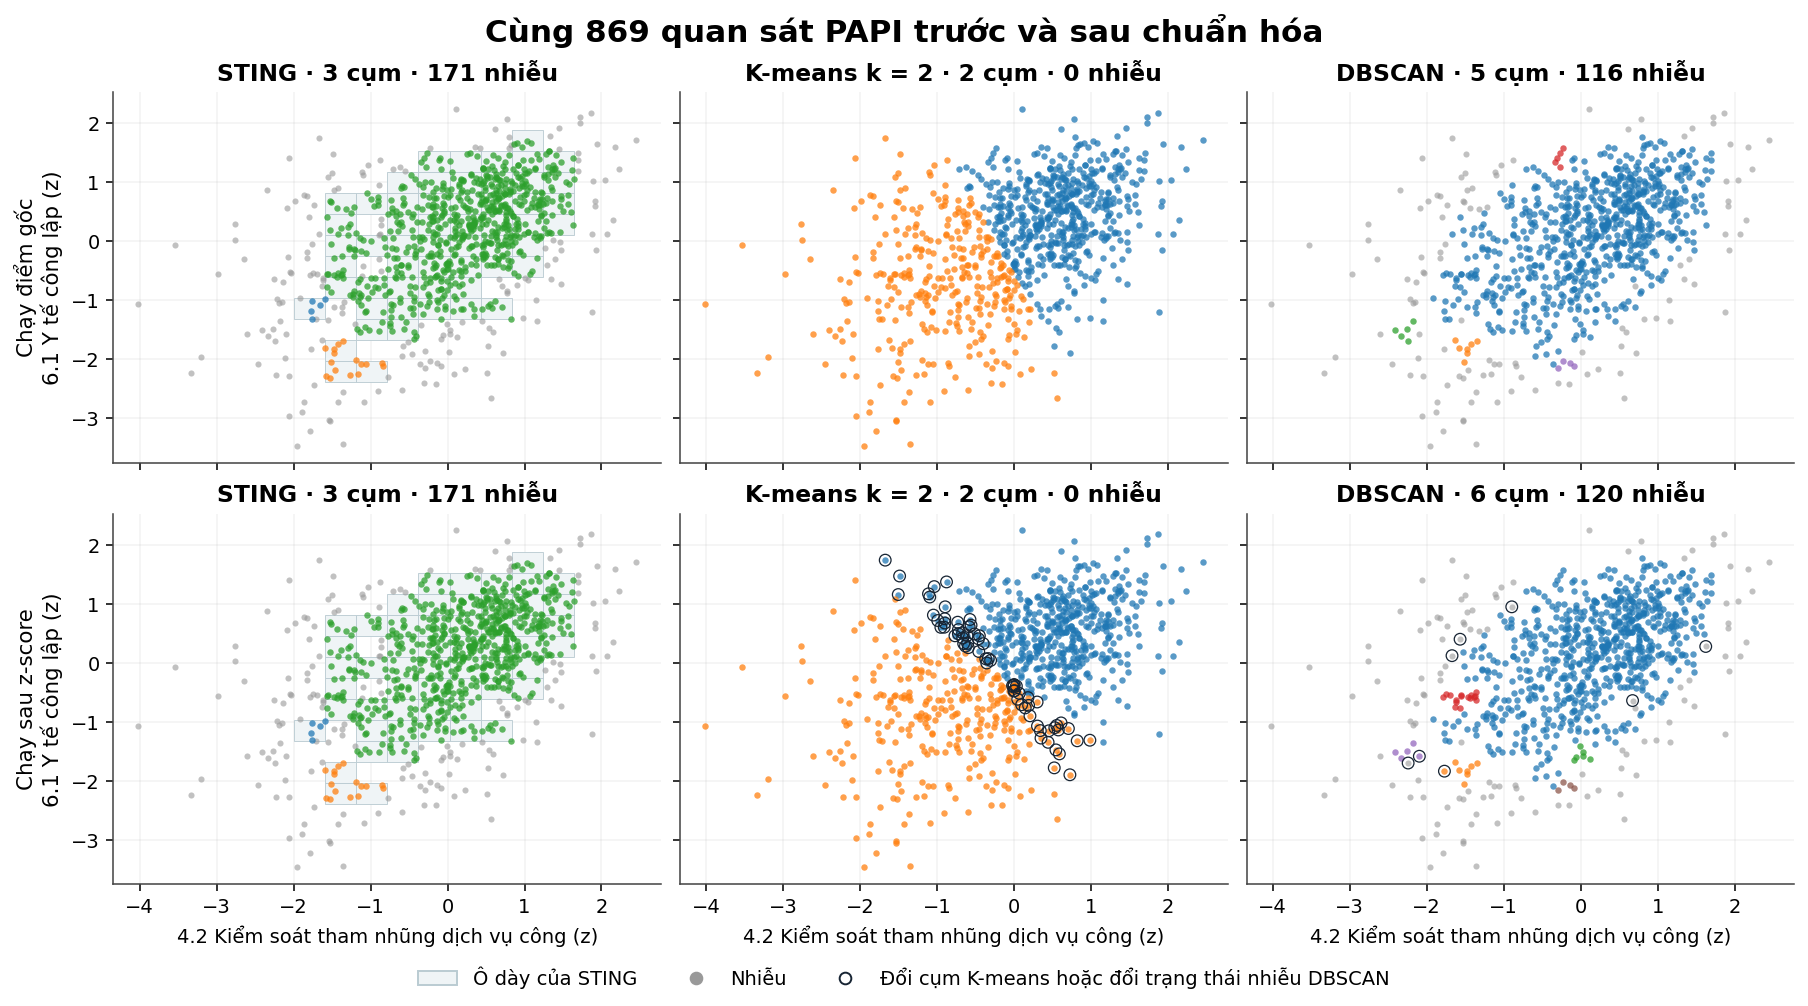

In [17]:
fig = scaling_comparison_figure(Xz, grid_model, (
    ("STING", raw_labels, lab, raw_labels != lab),
    ("K-means k = 2", km2_raw, km2_display, km_changed),
    ("DBSCAN", db_raw, db.labels_, db_changed),
))
plt.show()

### 4.7 Kiểm tra hai cách thay tiêu chí ô dày

**Đổi số điểm tối thiểu.** Giữ dữ liệu, trạng thái chuẩn hóa, mức lưới, biên và
quy tắc kề cạnh. Thử 3, 5 và 8 để quan sát số cụm và tỷ lệ điểm nhiễu thay đổi.

**Đổi mức lưới.** Giữ ngưỡng 5, biên và quy tắc kề cạnh. So sánh mức 0,
1 và 2 để xem dữ liệu được chia ra sao khi ô nhỏ dần.

**Đổi quy tắc kề cạnh.** Giữ lưới 16 × 16 và ngưỡng 5, thử nối cả ô chạm góc (`connectivity=2`).

In [18]:
for threshold in THRESHOLDS:
    trial, trial_labels = fit_grid(Xz, min_count=threshold)
    noise_count = int((trial_labels == -1).sum())
    print(f"Ngưỡng {threshold}  |  {trial.n_clusters_} cụm  |  "
          f"{noise_count}/{len(trial_labels)} nhiễu ({noise_count / len(trial_labels):.1%})")

levels = STING(n_levels=GRID["n_levels"], factor=GRID["factor"], min_count=GRID["min_count"]).fit(Xz)
for grid_level in range(levels.n_levels):
    level_labels = levels.cluster(level=grid_level, connectivity=GRID["connectivity"])
    width = levels.factor**grid_level
    print(f"Lưới {width} × {width} | {len(levels.label_of_)} ô dày | "
          f"{levels.n_clusters_} cụm | {int((level_labels == -1).sum())}/{len(level_labels)} điểm nhiễu")
corner_labels = levels.cluster(level=GRID["cluster_level"], connectivity=2)
print(f"Kề 8 hướng (connectivity=2) | {len(levels.label_of_)} ô dày | "
      f"{levels.n_clusters_} cụm | {int((corner_labels == -1).sum())}/{len(corner_labels)} điểm nhiễu")

Ngưỡng 3  |  3 cụm  |  85/869 nhiễu (9.8%)
Ngưỡng 5  |  3 cụm  |  171/869 nhiễu (19.7%)
Ngưỡng 8  |  1 cụm  |  271/869 nhiễu (31.2%)
Lưới 1 × 1 | 1 ô dày | 1 cụm | 0/869 điểm nhiễu
Lưới 4 × 4 | 12 ô dày | 1 cụm | 6/869 điểm nhiễu
Lưới 16 × 16 | 56 ô dày | 3 cụm | 171/869 điểm nhiễu
Kề 8 hướng (connectivity=2) | 56 ô dày | 1 cụm | 171/869 điểm nhiễu


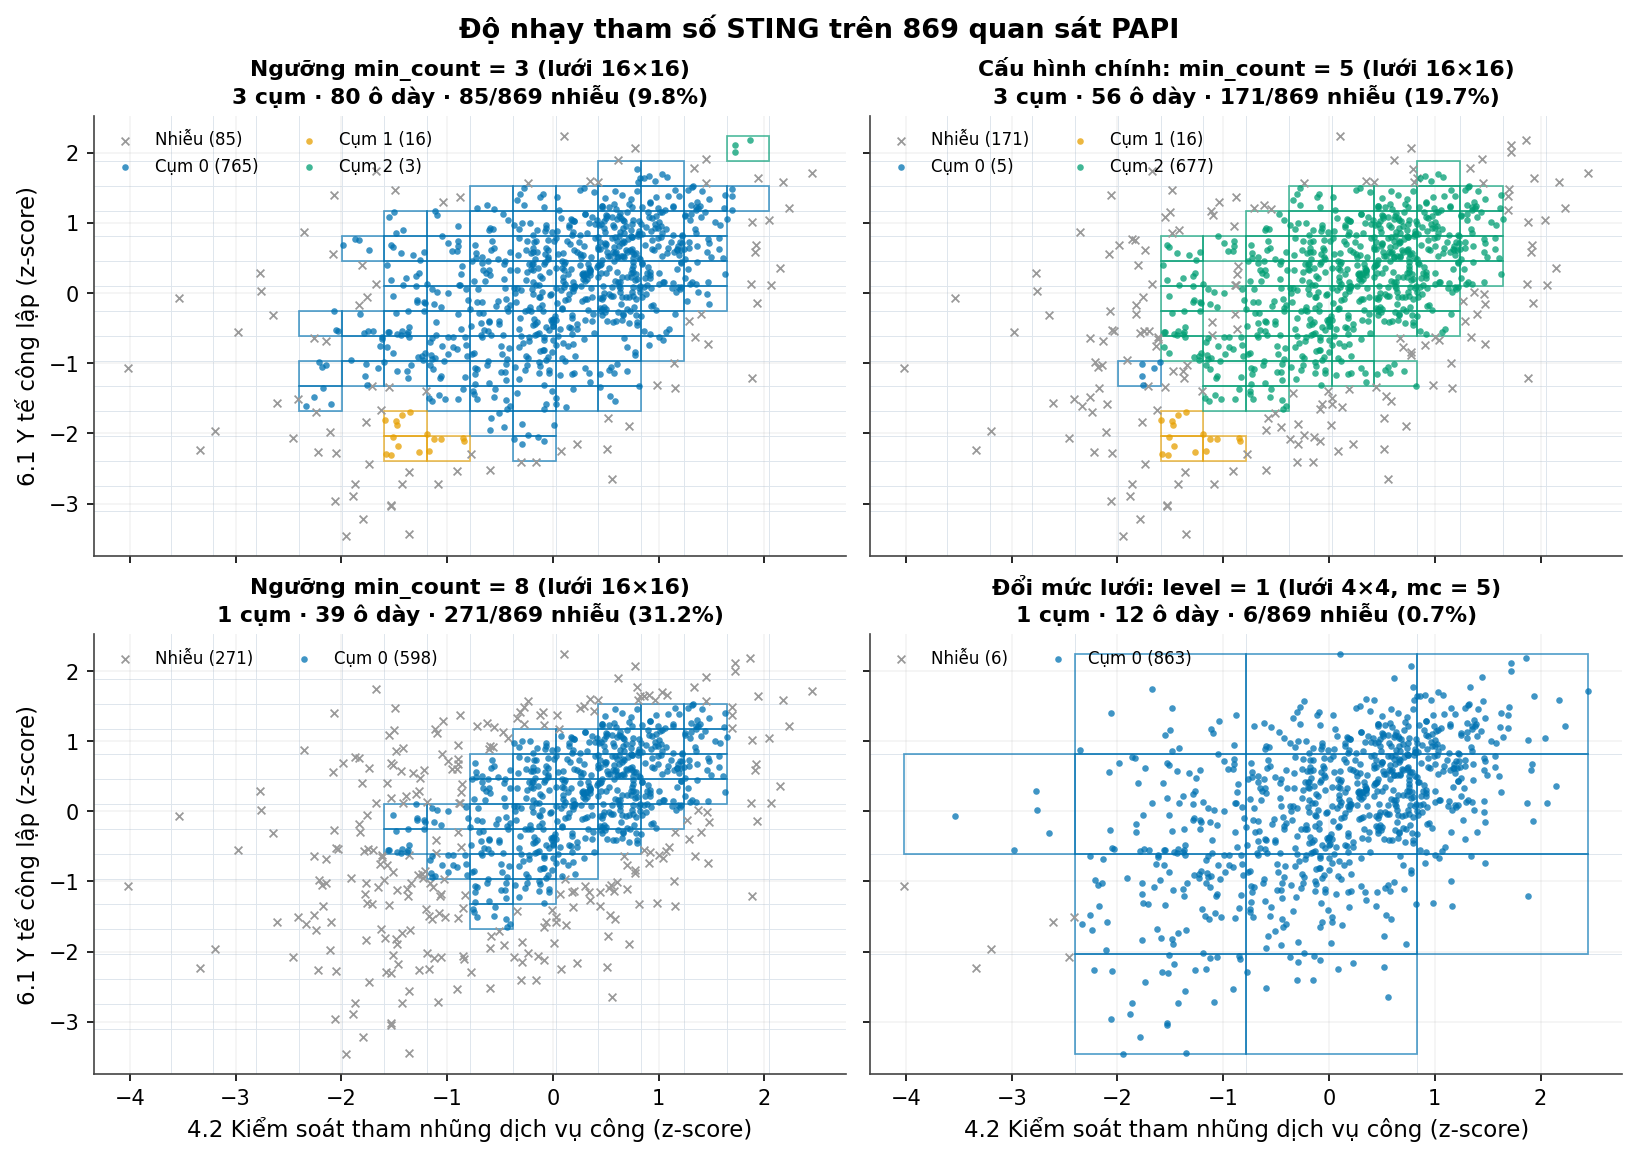

In [19]:
fig = sensitivity_grid_figure(Xz)
plt.show()

**Thử thêm ngưỡng so ô con với ô cha.** Tham số tùy chọn
**significance_z** của bản cài đặt áp dụng sau khi ô đạt tối thiểu 5 điểm.
Ô đạt thêm điều kiện nếu có ít nhất một chỉ tiêu thỏa

**|trung bình ô con − trung bình ô cha| > t × độ lệch chuẩn ô cha / √(số điểm ô con).**

Phép thử dùng **t = 2,0** để khảo sát ô nào còn lại sau lọc. Vì ô cha chứa
cả điểm của ô con, kết quả chỉ mô tả thay đổi của lưới và được đọc theo
số ô giữ lại. Kết quả chính dùng quy tắc đếm điểm với `significance_z=None`.
Z-score ở mục 4.2 vẫn là phép đổi tọa độ của từng quan sát.

In [20]:
filtered, filtered_labels = fit_grid(Xz, significance_z=CELL_Z_EXAMPLE)
print(f"Thêm significance_z={CELL_Z_EXAMPLE:.1f}: {len(filtered.label_of_)} ô đạt, "
      f"{filtered.n_clusters_} cụm, {int((filtered_labels == -1).sum())}/{len(lab)} điểm nhiễu.")

child = cell_stats[example_cell]
parent_key = tuple(i // GRID["factor"] for i in example_cell)
parent = grid_model.cells_[level - 1][parent_key]
gap = np.abs(child.mean - parent.mean)
cutoff = CELL_Z_EXAMPLE * parent.std / np.sqrt(child.count)
satisfied = gap > cutoff
assert bool(satisfied.any()) == (example_cell in filtered.label_of_)
print(f"Ô chứa Lạng Sơn 2024: ô con {example_cell}, ô cha {parent_key}.")
display(pd.DataFrame({"Chỉ tiêu": feats, "Chênh lệch tuyệt đối": gap,
                      "Mức so sánh": cutoff, "Đạt": satisfied}).round(4))

Thêm significance_z=2.0: 46 ô đạt, 4 cụm, 270/869 điểm nhiễu.
Ô chứa Lạng Sơn 2024: ô con (12, 10), ô cha (3, 2).


,Chỉ tiêu,Chênh lệch tuyệt đối,Mức so sánh,Đạt
0,sd_4_2,0.2198,0.1415,True
1,sd_6_1,0.0227,0.1748,False


### 4.8 Gán quan sát năm 2024 lên lưới cố định

Nhóm dựng lưới từ dữ liệu 2011–2023, rồi đặt hai điểm PAPI đã quan sát năm
2024 của từng tỉnh vào lưới đó. Hình cho thấy độ phủ của vùng dày và vị trí
của từng điểm. Một cụm STING có thể gồm nhiều ô dày nối với nhau qua cạnh.
Điểm của một tỉnh có thể sang ô khác giữa hai năm và vẫn thuộc cùng cụm.

| Mẫu | Cách dùng |
|---|---|
| 869 quan sát tỉnh–năm 2011–2024 | Dựng lưới phân cụm mô tả ở mục 4.3. |
| 808 quan sát tỉnh–năm đến 2023 | Dựng lưới tham chiếu cho mục này. |
| 61 tỉnh đủ hai chỉ tiêu năm 2024 | Gán vào lưới tham chiếu và đo độ phủ. |
| 59 tỉnh đủ dữ liệu ở cả hai năm | Theo dõi một tỉnh đổi ô và đổi vùng. |

**Vì sao xử lý dữ liệu rồi vẫn có điểm nhiễu?** Hai tỉnh thiếu chỉ tiêu
được loại khỏi phép gán. Cả 13 tỉnh mang nhãn −1 đều đủ hai điểm và
nằm trong ô có dưới 5 quan sát tham chiếu. Bảng bên dưới ghi rõ lý do và
số quan sát có sẵn trong ô của từng tỉnh — trong đó có cả các tỉnh đạt
điểm rất cao ở rìa phải/trên (Hà Tĩnh, Bình Thuận, Sóc Trăng, Bà Rịa - Vũng Tàu,
Quảng Ninh, Tây Ninh) lẫn các tỉnh thấp hơn ở chỉ tiêu 6.1 (Hà Nội, Cần Thơ),
chứ nhãn −1 không đồng nghĩa tỉnh quản trị yếu kém. Giữ các điểm ô thưa giúp
tính độ phủ trên đủ 61 tỉnh và tìm các trường hợp cần đối chiếu với số liệu gốc.

Để theo dõi thay đổi, ghép theo mã tỉnh và giữ những tỉnh đủ hai chỉ tiêu
ở cả hai năm. Cả hai lần gán đều dùng chung biên lưới, ngưỡng và cách nối ô.

Lưới tham chiếu dùng 808 quan sát 2011–2023.
48/61 tỉnh đủ hai chỉ tiêu vào cụm (78.7%).
48 điểm nằm ở 21 ô dày thuộc 1 cụm.


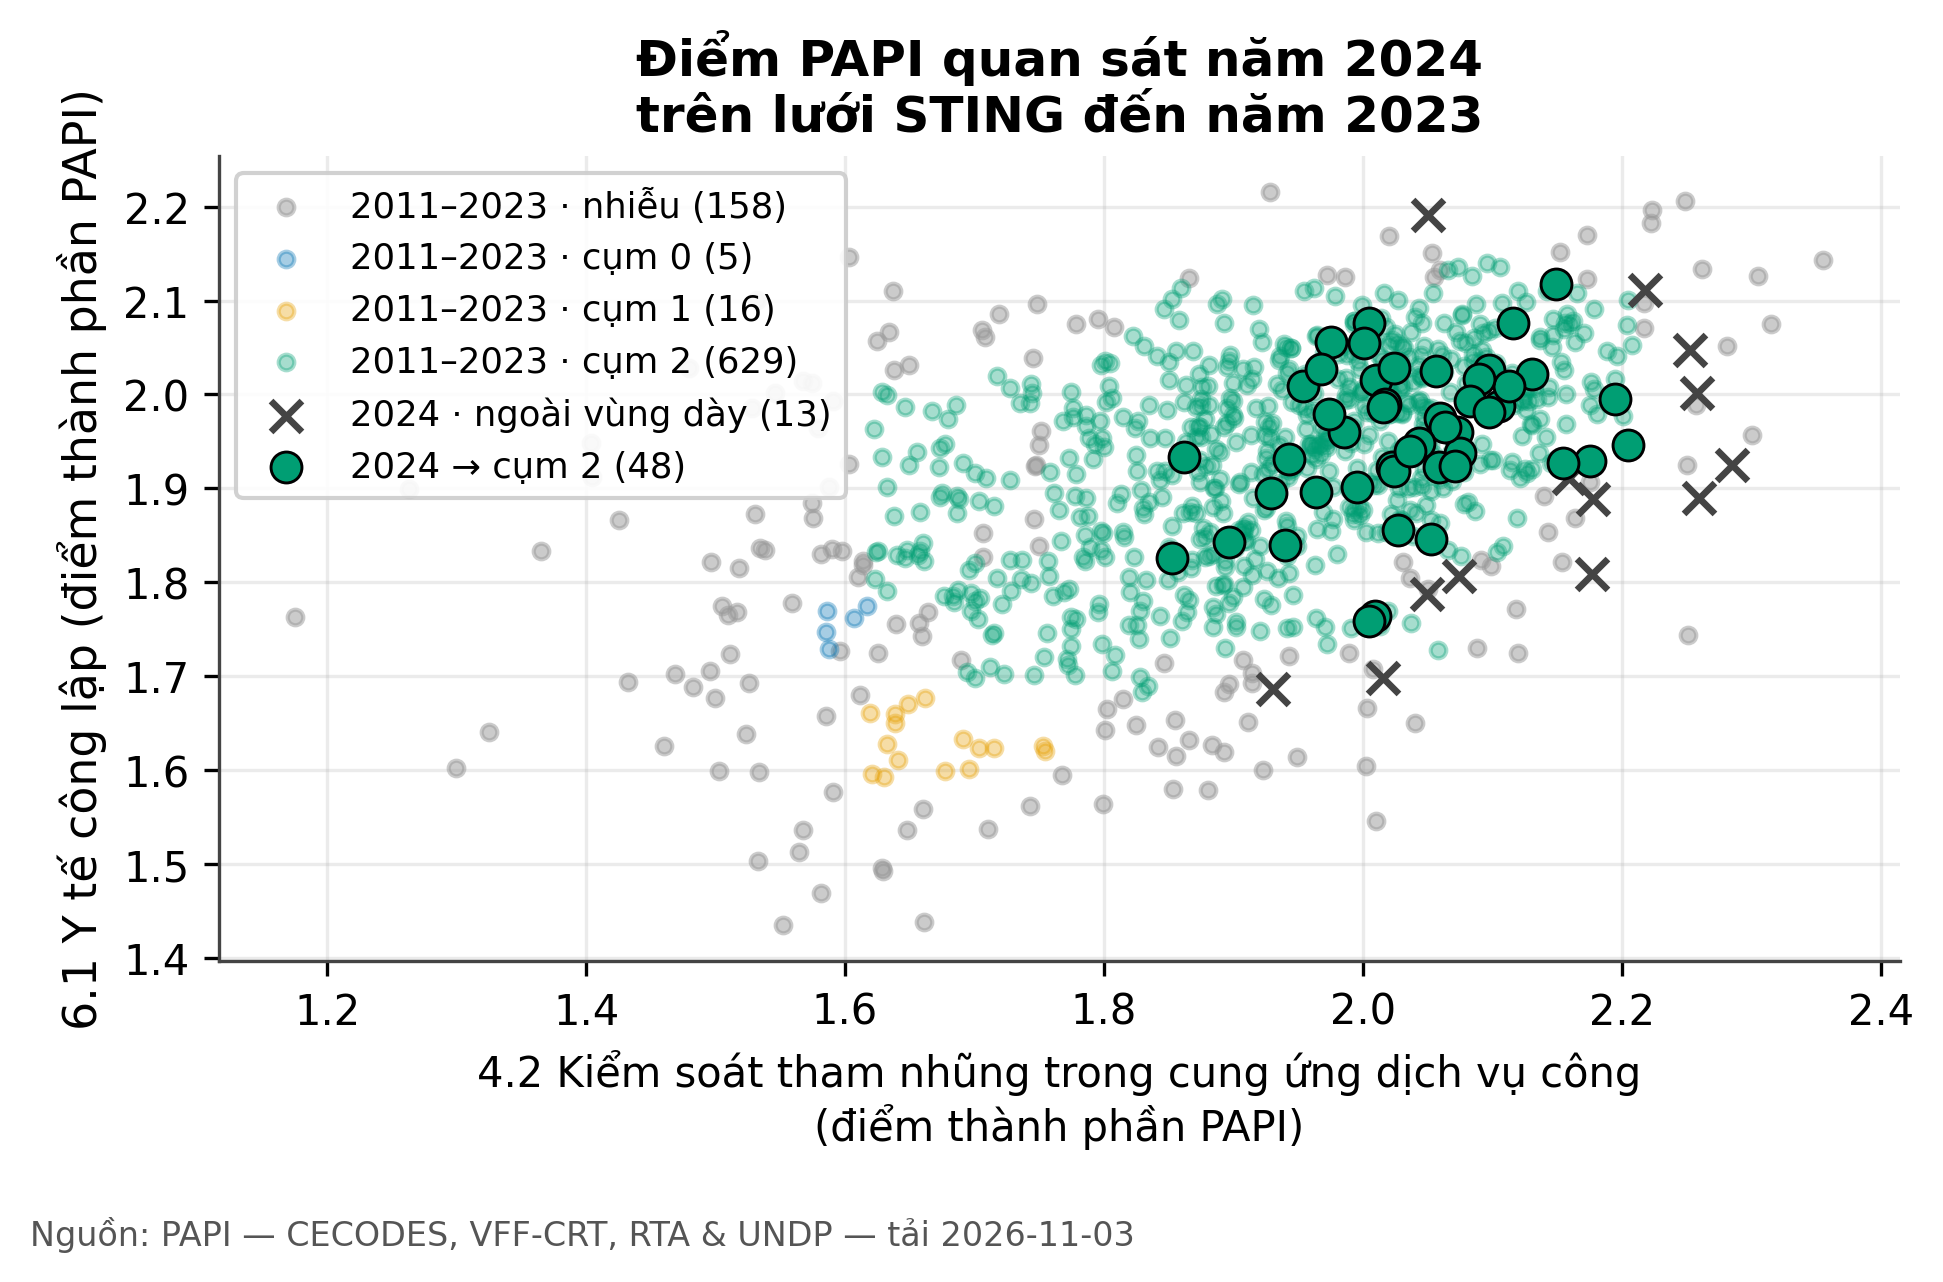

,Số tỉnh
Kết quả gán,
Thuộc cụm,48
Ô thưa,13
Thiếu chỉ tiêu,2


Cả 13/13 tỉnh ô thưa năm 2024 đều có |z| ≤ 3 trên lưới tham chiếu (|z| lớn nhất = 2.1299).


,Tỉnh/thành phố,Điểm 4.2,Điểm 6.1,|z| lớn nhất,Ô lưới,Số điểm tham chiếu,Lý do
0,Hà Nội,1.9308,1.6863,1.5792,"(10, 5)",3,Ô thưa
1,Quảng Ninh,2.2598,1.8891,1.9907,"(14, 9)",0,Ô thưa
2,Vĩnh Phúc,NaN,NaN,NaN,<NA>,<NA>,Thiếu chỉ tiêu
3,Hà Tĩnh,2.0502,2.1914,2.0571,"(11, 15)",1,Ô thưa
4,Bình Thuận,2.2182,2.1117,1.7625,"(14, 13)",2,Ô thưa
5,Gia Lai,2.0496,1.7875,0.8504,"(11, 7)",3,Ô thưa
6,Tây Ninh,2.2852,1.9245,2.1299,"(15, 10)",1,Ô thưa
7,Bình Dương,2.1768,1.8083,1.5351,"(13, 7)",1,Ô thưa
8,Bà Rịa - Vũng Tàu,2.2581,2.0017,1.9811,"(14, 11)",1,Ô thưa
9,Long An,2.0740,1.8069,0.9715,"(12, 7)",2,Ô thưa


In [21]:
from scripts.common.papi_pred_common import GRID_ASSIGNMENT_LABELS

assignments, reference_count = reference_grid_assignments(panel, reference_year=2023)
observed_grid = assignments.loc[assignments.year.eq(2024)]
eligible_2024 = observed_grid.dropna(subset=["cluster"])
clustered_2024 = eligible_2024.loc[eligible_2024.cluster.ge(0)]
print(f"Lưới tham chiếu dùng {reference_count} quan sát 2011–2023.")
print(f"{len(clustered_2024)}/{len(eligible_2024)} tỉnh đủ hai chỉ tiêu vào cụm "
      f"({len(clustered_2024) / len(eligible_2024):.1%}).")
print(f"{len(clustered_2024)} điểm nằm ở {clustered_2024.grid_cell.nunique()} ô dày "
      f"thuộc {clustered_2024.cluster.nunique()} cụm.")
display(Image(filename=str(ROOT / "results/figs/predict_2024.png")))
status_counts = observed_grid.grid_status.value_counts().rename(index=GRID_ASSIGNMENT_LABELS)
display(status_counts.rename("Số tỉnh").rename_axis("Kết quả gán").to_frame())
ref_scores = panel.loc[panel.year.le(2023), feats].dropna()
ref_scaler = StandardScaler().fit(ref_scores)
review = observed_grid.loc[observed_grid.grid_status.ne("in_cluster")].copy()
valid_review = review[feats].notna().all(axis=1)
review["max_abs_z"] = np.nan
review.loc[valid_review, "max_abs_z"] = np.abs(ref_scaler.transform(review.loc[valid_review, feats])).max(axis=1)
sparse_2024 = review.loc[review.grid_status.eq("sparse_cell")]
assert (sparse_2024["max_abs_z"] <= 3).all()
print(f"Cả {len(sparse_2024)}/{len(sparse_2024)} tỉnh ô thưa năm 2024 đều có |z| ≤ 3 "
      f"trên lưới tham chiếu (|z| lớn nhất = {sparse_2024['max_abs_z'].max():.4f}).")
review["grid_status"] = review.grid_status.map(GRID_ASSIGNMENT_LABELS)
display(review[["province_vi", *feats, "max_abs_z", "grid_cell", "reference_count", "grid_status"]].rename(columns={
    "province_vi": "Tỉnh/thành phố", "sd_4_2": "Điểm 4.2", "sd_6_1": "Điểm 6.1",
    "max_abs_z": "|z| lớn nhất", "grid_cell": "Ô lưới",
    "reference_count": "Số điểm tham chiếu", "grid_status": "Lý do",
}).round(4).reset_index(drop=True))

In [22]:
eligible_2023 = assignments.loc[assignments.year.eq(2023)].dropna(subset=["cluster"])
paired = eligible_2023.merge(eligible_2024, on="province_code", suffixes=("_2023", "_2024"), validate="one_to_one")
transition = pd.crosstab(paired.cluster_2023, paired.cluster_2024,
                         rownames=["Nhãn năm 2023"], colnames=["Nhãn năm 2024"])
print(f"Ghép được {len(paired)} tỉnh đủ chỉ tiêu ở cả hai năm. Nhãn −1 là ngoài vùng dày.")
unmatched = eligible_2024.loc[~eligible_2024.province_code.isin(paired.province_code), "province_vi"]
print(f"Đủ điểm 2024 nhưng thiếu điểm ghép năm 2023: {', '.join(unmatched)}.")
display(transition)
same_cluster = paired.loc[paired.cluster_2023.ge(0) & paired.cluster_2023.eq(paired.cluster_2024)]
changed_cells = same_cluster.grid_cell_2023.ne(same_cluster.grid_cell_2024).sum()
print(f"{changed_cells}/{len(same_cluster)} tỉnh giữ nguyên cụm nhưng đổi ô.")

example = assignments.loc[assignments.province_vi.eq("Lạng Sơn")].sort_values("year")
for row in example.itertuples(index=False):
    region = "ngoài vùng dày" if row.cluster == -1 else f"cụm {row.cluster}"
    print(f"Lạng Sơn {row.year}: {region} trên cùng lưới đến năm 2023. "
          f"Ô {row.grid_cell} có {row.reference_count} điểm tham chiếu.")

Ghép được 59 tỉnh đủ chỉ tiêu ở cả hai năm. Nhãn −1 là ngoài vùng dày.


Đủ điểm 2024 nhưng thiếu điểm ghép năm 2023: Quảng Ninh, Bình Dương.


Nhãn năm 2024,-1,2
Nhãn năm 2023,,
-1,4,5
2,7,43


39/43 tỉnh giữ nguyên cụm nhưng đổi ô.
Lạng Sơn 2023: ngoài vùng dày trên cùng lưới đến năm 2023. Ô (13, 9) có 2 điểm tham chiếu.
Lạng Sơn 2024: cụm 2 trên cùng lưới đến năm 2023. Ô (12, 10) có 12 điểm tham chiếu.


## 5. Kết luận và hạn chế

Trên dữ liệu giả lập, STING đạt ARI 0,950 khi đối chiếu với nhãn tham chiếu.
Trên 869 quan sát PAPI 2011–2024, ở ngưỡng 5, ba cụm STING có 677, 16 và
5 điểm. Cụm lớn chiếm khoảng 97% trong số 698 điểm được gán cụm. Còn
171 điểm (19,7% toàn mẫu) nằm trong các ô thưa. Kết quả nổi bật là một
vùng tập trung lớn và hai vùng nhỏ. Ở ngưỡng 8, kết quả còn một cụm.

K-means k = 2 chia 677 điểm ở vùng STING lớn nhất thành hai phần gồm
482 và 195 điểm. Ở cấu hình đang dùng, z-score giữ nguyên chỉ số ô STING
vì hai lưới đều dựng lại theo biên từng trục. Kết quả K-means có thể đổi
do phép chuẩn hóa thay đổi khoảng cách. So sánh silhouette dựa trên nhóm
điểm được cả ba phương pháp gán cụm, nên kết quả mô tả phần dữ liệu này.
Mỗi cụm gồm các quan sát tỉnh–năm. Diễn giải giới hạn trong hai chỉ tiêu,
giai đoạn và cấu hình đã xét.

Lưới cố định giúp theo dõi một tỉnh qua hai năm ở cả cấp ô và cấp cụm.
Đổi ô cho thấy hai điểm PAPI đã dịch chuyển qua một đường biên lưới.
Việc diễn giải mức độ thay đổi cần đọc cùng hai giá trị điểm gốc.

**Nguồn tham khảo**

- Wang, Yang và Muntz (1997), bài báo về lưới thống kê STING tại VLDB.
  [Bài báo gốc](https://www.vldb.org/conf/1997/P186.PDF)
- Dữ liệu PAPI 2011–2024 do CECODES, VFF-CRT, RTA và UNDP công bố.
  [Nguồn dữ liệu PAPI](https://papi.org.vn/du-lieu-papi/)
- Công cụ chuẩn hóa và thước đo so sánh từ scikit-learn 1.8.
  [StandardScaler](https://scikit-learn.org/1.8/modules/generated/sklearn.preprocessing.StandardScaler.html) ·
  [Silhouette](https://scikit-learn.org/1.8/modules/generated/sklearn.metrics.silhouette_score.html) ·
  [ARI](https://scikit-learn.org/1.8/modules/generated/sklearn.metrics.adjusted_rand_score.html)
- Le và cộng sự (2026), dữ liệu đối chiếu các chỉ số nội dung PAPI.
  [Mendeley Data, DOI 10.17632/wbk42j9wc8.1](https://data.mendeley.com/datasets/wbk42j9wc8/1)